# Lab | Time Series Analysis

## Before your start:
- Read the README.md file
- Comment as much as you can and use the resources (README.md file)
- Happy learning!

In [1]:
# Import numpy and pandas
import pandas as pd
import numpy as np

## Challenge 1 - Loading and Evaluating The Data

In this lab, we will look at a dataset of sensor data from a cellular phone. The phone was carried in the subject's pocket for a few minutes while they walked around.

To load the data, run the code below.

In [2]:
# Run this code:

sensor = pd.read_csv('../data/sub_1.csv')
sensor.drop(columns=['Unnamed: 0'], inplace=True)

Examine the data using the `head` function.

In [3]:
# Your code here:
sensor.head()


,attitude.roll,attitude.pitch,attitude.yaw,gravity.x,gravity.y,gravity.z,rotationRate.x,rotationRate.y,rotationRate.z,userAcceleration.x,userAcceleration.y,userAcceleration.z
0,1.528132,-0.733896,0.696372,0.741895,0.669768,-0.031672,0.316738,0.778180,1.082764,0.294894,-0.184493,0.377542
1,1.527992,-0.716987,0.677762,0.753099,0.657116,-0.032255,0.842032,0.424446,0.643574,0.219405,0.035846,0.114866
2,1.527765,-0.706999,0.670951,0.759611,0.649555,-0.032707,-0.138143,-0.040741,0.343563,0.010714,0.134701,-0.167808
3,1.516768,-0.704678,0.675735,0.760709,0.647788,-0.041140,-0.025005,-1.048717,0.035860,-0.008389,0.136788,0.094958
4,1.493941,-0.703918,0.672994,0.760062,0.647210,-0.058530,0.114253,-0.912890,0.047341,0.199441,0.353996,-0.044299


Check whether there is any missing data. If there is any missing data, remove the rows containing missing data.

In [6]:
# Your code here:
sensor.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1751 entries, 0 to 1750
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   attitude.roll       1751 non-null   float64
 1   attitude.pitch      1751 non-null   float64
 2   attitude.yaw        1751 non-null   float64
 3   gravity.x           1751 non-null   float64
 4   gravity.y           1751 non-null   float64
 5   gravity.z           1751 non-null   float64
 6   rotationRate.x      1751 non-null   float64
 7   rotationRate.y      1751 non-null   float64
 8   rotationRate.z      1751 non-null   float64
 9   userAcceleration.x  1751 non-null   float64
 10  userAcceleration.y  1751 non-null   float64
 11  userAcceleration.z  1751 non-null   float64
dtypes: float64(12)
memory usage: 164.3 KB


How many rows and columns are in our data?

In [8]:
# Your code here:
sensor.shape


(1751, 12)

To perform time series analysis on the data, we must change the index from a range index to a time series index. In the cell below, create a time series index using the `pd.date_range` function. Create a time series index starting at 1/1/2018 00:00:00 and ending at 1/1/2018 00:29:10. The number of periods is equal to the number of rows in `sensor`. The frequency should be set to `infer`.

In [10]:
# Your code here:
sensor.index = pd.date_range(start="1/1/2018 00:00:00", end="1/1/2018 00:29:10", periods=len(sensor))


Assign the time series index to the dataframe's index.

In [11]:
# Your code here:
print(sensor.index.inferred_freq)


s


Our next step is to decompose the time series and evaluate the patterns in the data. Load the `statsmodels.api` submodule and plot the decomposed plot of `userAcceleration.x`. Set `freq=60` in the `seasonal_decompose` function. Your graph should look like the one below.

![time series decomposition](./images/tsa_decompose.png)

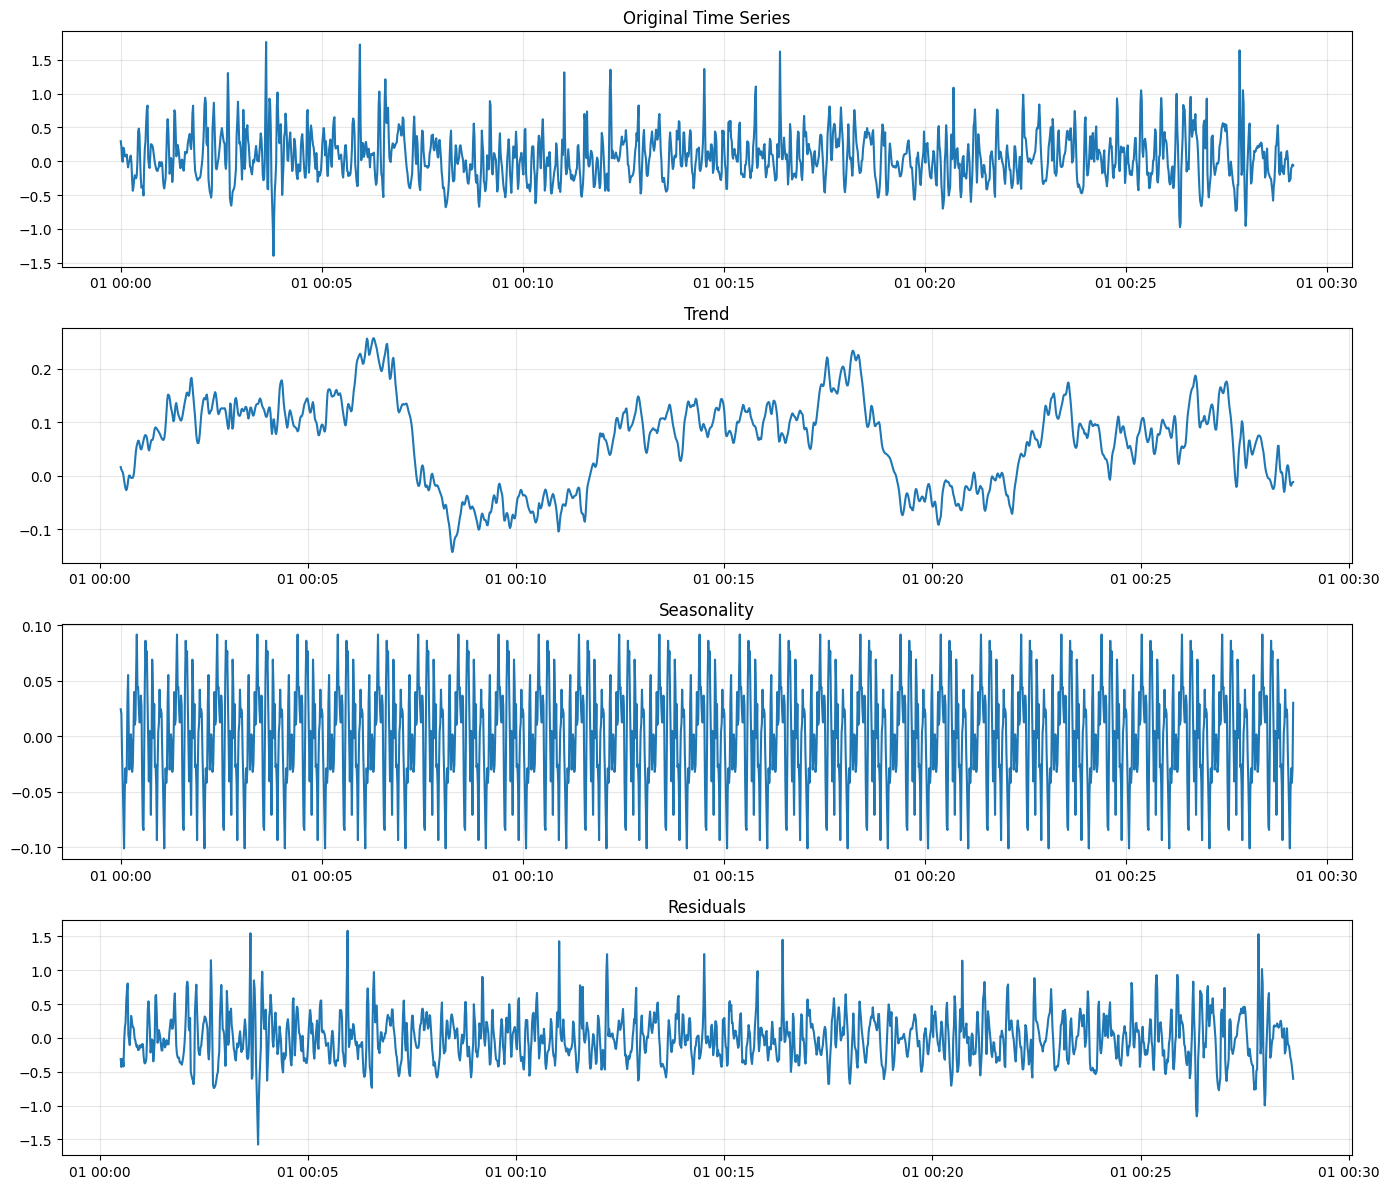

In [23]:
# Your code here:
import statsmodels.api as sm
import matplotlib.pyplot as plt

result = sm.tsa.seasonal_decompose(sensor['userAcceleration.x'] , period=60)

plt.figure(figsize=(14, 12))
plt.subplot(411)
plt.plot(result.observed)
plt.title('Original Time Series')
plt.grid(True, alpha=0.3)

plt.subplot(412)
plt.plot(result.trend)
plt.title('Trend')
plt.grid(True, alpha=0.3)

plt.subplot(413)
plt.plot(result.seasonal)
plt.title('Seasonality')
plt.grid(True, alpha=0.3)

plt.subplot(414)
plt.plot(result.resid)
plt.title('Residuals')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Plot the decomposed time series of `rotationRate.x` also with a frequency of 60.

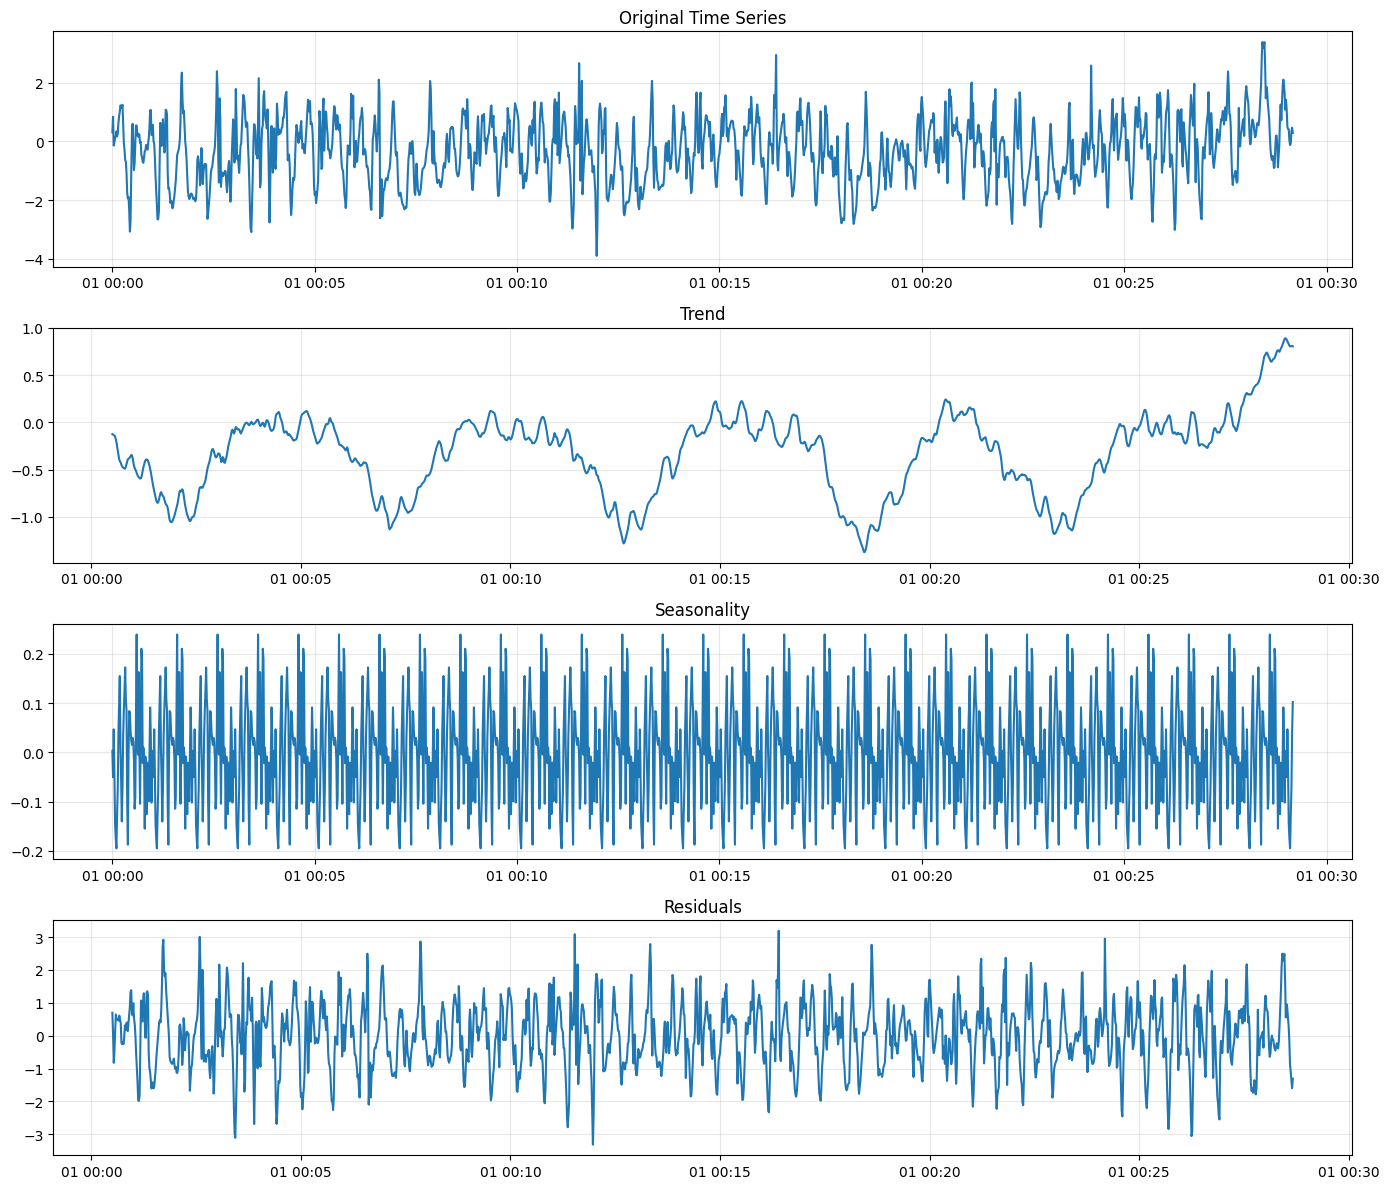

In [24]:
result = sm.tsa.seasonal_decompose(sensor['rotationRate.x'] , period=60)

plt.figure(figsize=(14, 12))
plt.subplot(411)
plt.plot(result.observed)
plt.title('Original Time Series')
plt.grid(True, alpha=0.3)

plt.subplot(412)
plt.plot(result.trend)
plt.title('Trend')
plt.grid(True, alpha=0.3)

plt.subplot(413)
plt.plot(result.seasonal)
plt.title('Seasonality')
plt.grid(True, alpha=0.3)

plt.subplot(414)
plt.plot(result.resid)
plt.title('Residuals')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Challenge 2 - Modelling the Data

To model our data, we should look at a few assumptions. First, let's plot the `lag_plot` to detect any autocorrelation. Do this for `userAcceleration.x`

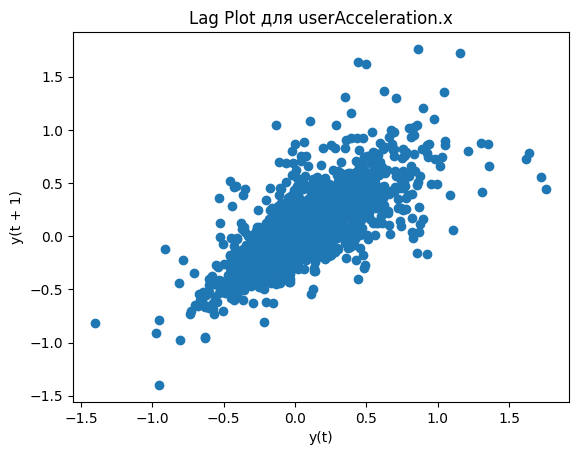

In [25]:

from pandas.plotting import lag_plot

lag_plot(sensor['userAcceleration.x'])
plt.title("Lag Plot для userAcceleration.x")
plt.show()


Create a lag plot for `rotationRate.x`

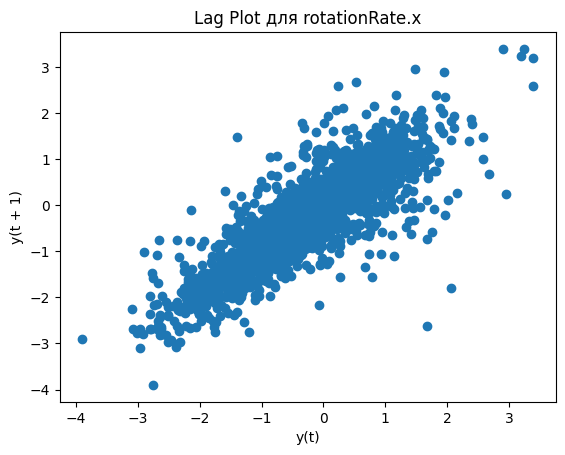

In [26]:
# Your code here:

lag_plot(sensor['rotationRate.x'])
plt.title("Lag Plot для rotationRate.x")
plt.show()

What are your conclusions from both visualizations?

In [ ]:
# Your conclusions here:
# The points on the lag plot are aligned along the diagonal, indicating that the time series values depend on their previous values.


The next step will be to test both variables for stationarity. Perform the Augmented Dickey Fuller test on both variables below.

In [29]:
# Your code here:
from statsmodels.tsa.stattools import adfuller


adf_result_ua = adfuller(sensor['userAcceleration.x'])
print("userAcceleration.x:")
print("ADF Statistic: %f" % adf_result_ua[0])
print("p-value: %f" % adf_result_ua[1])
print("Critical Values:")
for key, value in adf_result_ua[4].items():
    print("\t%s: %.3f" % (key, value))

print("\n" + "-"*50 + "\n")

adf_result_rr = adfuller(sensor['rotationRate.x'])
print("rotationRate.x:")
print("ADF Statistic: %f" % adf_result_rr[0])
print("p-value: %f" % adf_result_rr[1])
print("Critical Values:")
for key, value in adf_result_rr[4].items():
    print("\t%s: %.3f" % (key, value))



userAcceleration.x:
ADF Statistic: -17.957994
p-value: 0.000000
Critical Values:
	1%: -3.434
	5%: -2.863
	10%: -2.568

--------------------------------------------------

rotationRate.x:
ADF Statistic: -5.269861
p-value: 0.000006
Critical Values:
	1%: -3.434
	5%: -2.863
	10%: -2.568


What are your conclusions from this test?

In [18]:
# Your conclusions here:

# The results showed that the test statistic was significantly lower than the critical values, and the p-value was very small (close to zero).
#This allows us to reject the null hypothesis (the presence of a unit root) and conclude that the time series is indeed stationary.

Finally, we'll create an ARMA model for `userAcceleration.x`. Load the `ARMA` function from `statsmodels`. The order of the model is (2, 1). Split the data to train and test. Use the last 10 observations as the test set and all other observations as the training set. 

                               SARIMAX Results                                
Dep. Variable:     userAcceleration.x   No. Observations:                 1741
Model:                 ARIMA(2, 0, 1)   Log Likelihood                 373.401
Date:                Wed, 21 May 2025   AIC                           -736.803
Time:                        16:18:44   BIC                           -709.492
Sample:                    01-01-2018   HQIC                          -726.704
                         - 01-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0637      0.016      3.994      0.000       0.032       0.095
ar.L1          0.9882      0.036     27.630      0.000       0.918       1.058
ar.L2         -0.3788      0.033    -11.637      0.0

/Users/sergej/Library/Python/3.9/lib/python/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
/Users/sergej/Library/Python/3.9/lib/python/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
/Users/sergej/Library/Python/3.9/lib/python/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)


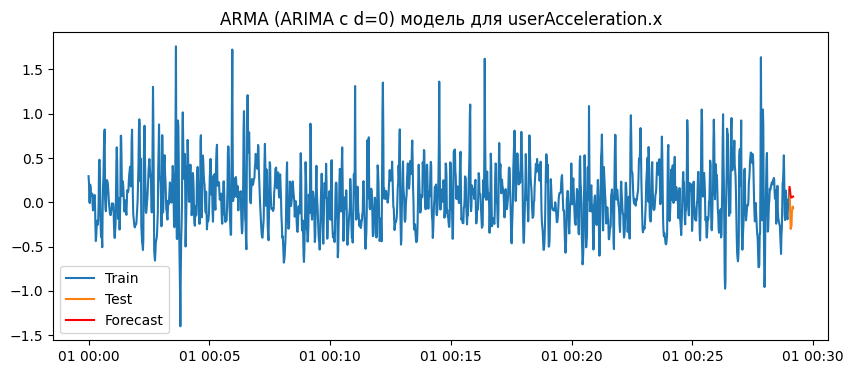

In [32]:
# Your code here:
from statsmodels.tsa.arima.model import ARIMA

train = sensor['userAcceleration.x'].iloc[:-10]
test = sensor['userAcceleration.x'].iloc[-10:]

arma_model = ARIMA(train, order=(2, 0, 1))
arma_result = arma_model.fit()

print(arma_result.summary())


forecast = arma_result.forecast(steps=10)

plt.figure(figsize=(10, 4))
plt.plot(train.index, train, label='Train')
plt.plot(test.index, test, label='Test')
plt.plot(test.index, forecast, label='Forecast', color='red')
plt.title("ARMA (ARIMA с d=0) модель для userAcceleration.x")
plt.legend()
plt.show()


To compare our predictions with the observed data, we can compute the RMSE (Root Mean Squared Error) from the submodule `statsmodels.tools.eval_measures`. You can read more about this function [here](https://www.statsmodels.org/dev/generated/statsmodels.tools.eval_measures.rmse.html). Compute the RMSE for the last 10 rows of the data by comparing the observed and predicted data for the `userAcceleration.x` column.

In [34]:
# Your code here:

from statsmodels.tools.eval_measures import rmse

# Calculate RMSE for the test set
error = rmse(test, forecast)
print(f"RMSE for the last 10 observations: {error:.4f}")



RMSE for the last 10 observations: 0.2253
